**Aim:** Integrate differential expressed genes (DEGs) from different comparisons.
**Tools**
- `limma` – gene level 
- `iPAGE` – pathway level

In [1]:
import pandas as pd 
from utils import find_top

from matplotlib import pyplot as plt
from venn import venn 

In [2]:
def read_diffexp_table(name):
    d = {
        'MethvsSaline':pd.read_csv(
            f'diffexp/{name}/delta_exp_MethvsSaline.txt',  sep='\t'),
        'MDMAvsSaline':pd.read_csv(
            f'diffexp/{name}/delta_exp_MDMAvsSaline.txt',sep='\t'),
        'MDMAvsMeth':pd.read_csv(
            f'diffexp/{name}/delta_exp_MDMAvsMeth.txt',  sep='\t')
    }

    out = pd.concat(d.values(), axis=1, keys=d.keys())
    out.index = out.index.str.upper()
    return out

## overlapping analysis

___
- generate similar diagram for MDMAvsMeth_up and SalinevsMeth_up
- look whether any of the 321 genes from the yellow circle in all_neurons overlap with any of the gens from the above analysis


___
We’re interested in genes which are higher in saline and lower in meth and the overlapping ones with MDMAvsMeth_up. 
However, you previously plotted MethvsSaline_up and overlapped it with MDMAvsMeth_up. If it is easier you could plot Meth vs Saline down as it should be similar to Saline vs Meth up. 


___
<!-- ___
>@ Abe: do you think you can generate a list with MDMA vs Meth up overlapped with Saline vs Meth up? It may not be any different but perhaps there’ll be some other hits that may turn out to be interesting?
 -->
Wed Nov  9 11:34:14 PST 2022
 
- Saba: annotate the 102 genes MDMAvsSaline_up & MDMAvsMeth_up with names and function (focus on neuronal genes, no need to annotate ubiquitously expressed genes such as actin, tubulin)
- Abe: bring analysis up to date and run DE analysis MDMAvsMeth, MDMAvsSaline, MethvsSaline. Run GO analysis.


In [3]:
fc_thr = 0.5
pv_thr = 0.05


diffexp = {}

for cond in ['all_neurons',
             'Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    print(cond)
    diffexp[cond] = {}
    for comp in ['MethvsSaline','MDMAvsMeth','MDMAvsSaline']:
        print(comp)
        up,down = find_top(
            read_diffexp_table(cond)[comp],
            'log2FoldChange',fc_thr,'pvalue',pv_thr
        )
        diffexp[cond][f'{comp}_up'] = set(up.index)
        diffexp[cond][f'{comp}_down'] = set(down.index)
    print(20*'__')

all_neurons
MethvsSaline
up:  1643
down: 765
MDMAvsMeth
up:  61
down: 85
MDMAvsSaline
up:  1597
down: 866
________________________________________
Astrocytes
MethvsSaline
up:  30
down: 211
MDMAvsMeth
up:  102
down: 35
MDMAvsSaline
up:  38
down: 136
________________________________________
Endothelial
MethvsSaline
up:  40
down: 127
MDMAvsMeth
up:  11
down: 266
MDMAvsSaline
up:  16
down: 423
________________________________________
Microglia
MethvsSaline
up:  28
down: 322
MDMAvsMeth
up:  9
down: 318
MDMAvsSaline
up:  6
down: 695
________________________________________
Oligodendrocytes
MethvsSaline
up:  330
down: 217
MDMAvsMeth
up:  16
down: 94
MDMAvsSaline
up:  170
down: 188
________________________________________


> - Meth & MDMA high and saline low
> - MDMA & saline high and Meth low


In [4]:
cmaps = ["cool", list("rgb"), "plasma", "viridis", "Set1"]

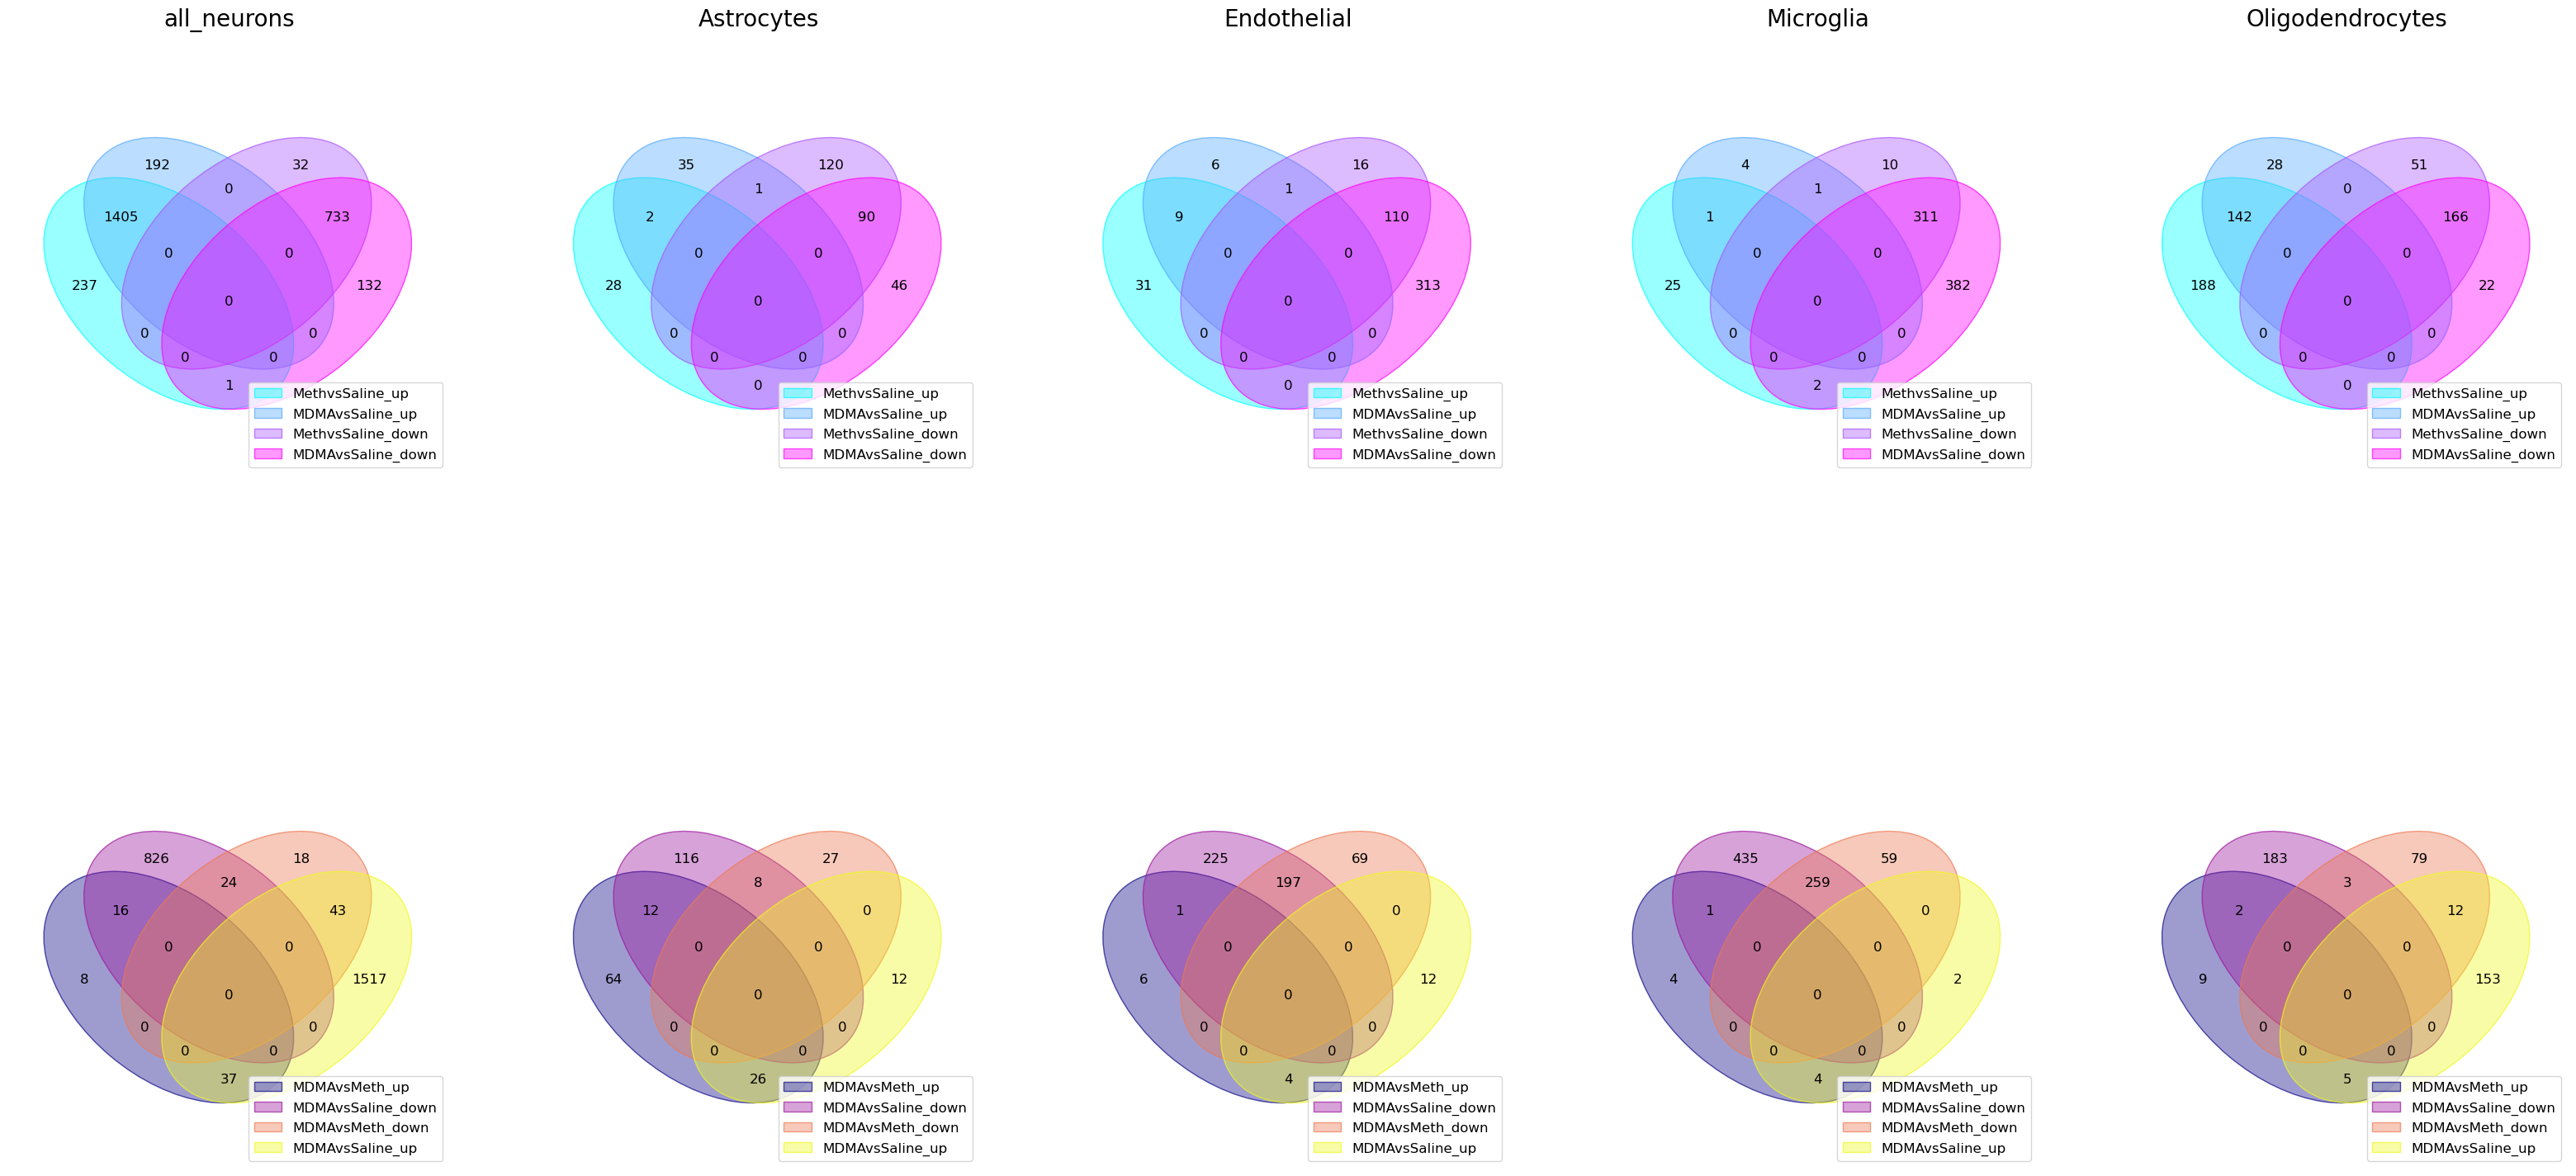

In [5]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(40, 20))

for cond,ax in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[0,[0,1,2,3,4]]):
    venn({comp: diffexp[cond][comp] for comp in ['MethvsSaline_up','MDMAvsSaline_up',
                                                'MethvsSaline_down','MDMAvsSaline_down']},
         ax=ax,legend_loc="lower right",fontsize=12,cmap=cmaps[0])
    ax.set_title(cond,fontsize=20)

for cond,ax in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[1,[0,1,2,3,4]]):
    venn({comp: diffexp[cond][comp] for comp in ['MDMAvsMeth_up','MDMAvsSaline_down',
                                                 'MDMAvsMeth_down','MDMAvsSaline_up'
                                                ]},
         ax=ax,legend_loc="lower right",fontsize=12,cmap=cmaps[2])
    # ax.set_title(cond,fontsize=20)
fig.savefig('diffexp/venn_full.pdf')
plt.show()

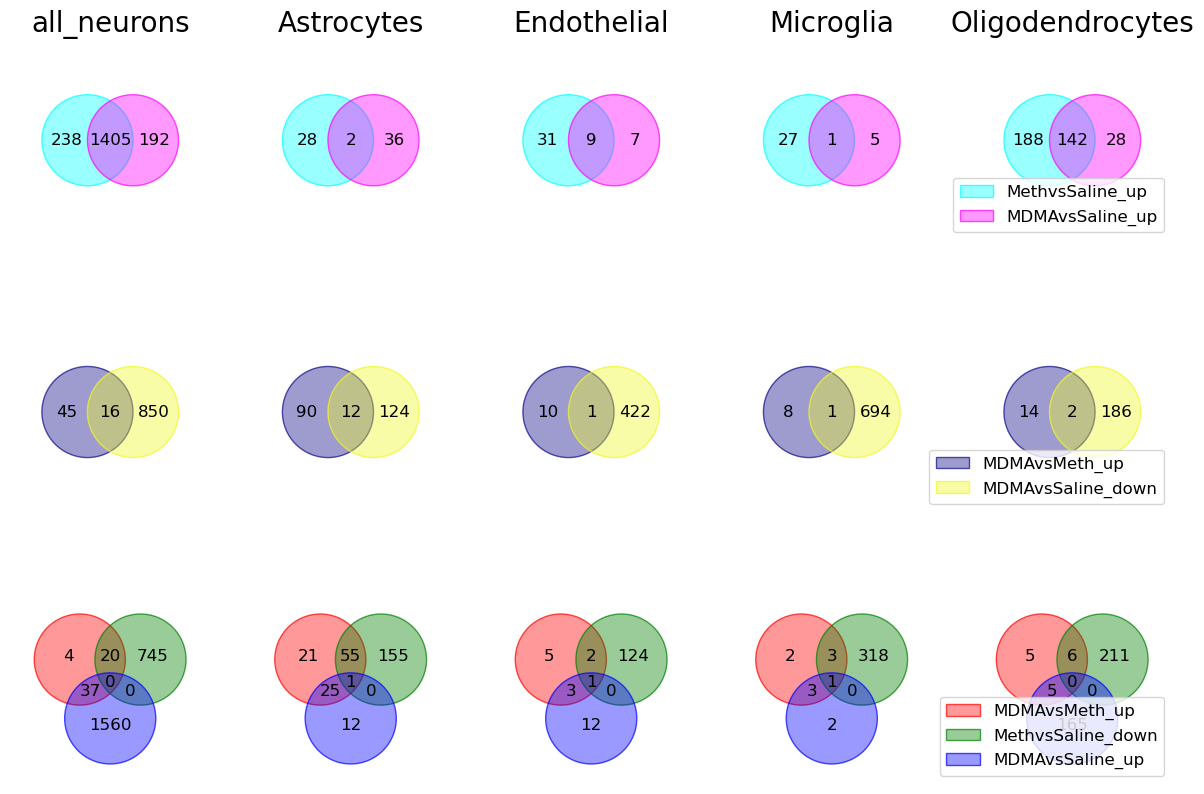

In [6]:
fig, axes = plt.subplots(ncols=5, nrows=3, figsize=(15, 10))

for cond,ax,l in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[0,[0,1,2,3,4]],[None,None,None,None,"lower right"]):
    venn({comp: diffexp[cond][comp] for comp in ['MethvsSaline_up','MDMAvsSaline_up']},
         ax=ax,legend_loc=l,fontsize=12,cmap=cmaps[0])
    ax.set_title(cond,fontsize=20)

for cond,ax,l in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[1,[0,1,2,3,4]],[None,None,None,None,"lower right"]):
    venn({comp: diffexp[cond][comp] for comp in ['MDMAvsMeth_up','MDMAvsSaline_down']},
         ax=ax,legend_loc=l,fontsize=12,cmap=cmaps[2])
    # ax.set_title(cond,fontsize=20)
    
for cond,ax,l in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[2,[0,1,2,3,4]],[None,None,None,None,"lower right"]):
    venn({comp: diffexp[cond][comp] for comp in ['MDMAvsMeth_up','MethvsSaline_down','MDMAvsSaline_up']},
         ax=ax,legend_loc=l,fontsize=12,cmap=cmaps[1])
    # ax.set_title(cond,fontsize=20)

fig.savefig('diffexp/venn.pdf')
plt.show()

In [7]:
overlaps = {}
for cond in ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    print(cond)
    A,B,C = ['MDMAvsMeth_up','MethvsSaline_down','MDMAvsSaline_up']
    a,b,c = [diffexp[cond][comp] for comp in [A,B,C]]

    overlaps[cond] = pd.concat({
        ## group 1
        f"{A}-{B}-{C}":pd.DataFrame({'genes':[gene for gene in a - b - c]}).set_index('genes'),
        ## group 2
        f"({A}&{B})-{C}":pd.DataFrame({'genes':[gene for gene in (a & b) - c]}).set_index('genes'),
        ## group 3
        f"({A}&{C})-{B}":pd.DataFrame({"genes":[gene for gene in (a & c) - b]}).set_index('genes'),
        ## group 4
        f"{A}&{B}&{C}":pd.DataFrame({"genes":[gene for gene in (a & b & c)]}).set_index('genes')
    })

all_neurons
Astrocytes
Endothelial
Microglia
Oligodendrocytes


In [8]:
pd.concat(overlaps)

Empty DataFrame
Columns: []
Index: [(all_neurons, MDMAvsMeth_up-MethvsSaline_down-MDMAvsSaline_up, HNRNPA1), (all_neurons, MDMAvsMeth_up-MethvsSaline_down-MDMAvsSaline_up, DDX3X), (all_neurons, MDMAvsMeth_up-MethvsSaline_down-MDMAvsSaline_up, IDI1), (all_neurons, MDMAvsMeth_up-MethvsSaline_down-MDMAvsSaline_up, MT-ND6), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, TUBB4B), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, PTGDS), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, CD9), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, MOBP), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, KLF9), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, DBI), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, GM10076), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, MBP), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, KLF2), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, DYNLL1), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, ARL4A), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, SGK1), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, EGR1), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, TUBA1A), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, KLF4), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, PNRC1), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, PLP1), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, STMN1), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, FOSB), (all_neurons, (MDMAvsMeth_up&MethvsSaline_down)-MDMAvsSaline_up, GSTA4), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, MLF1), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, SMC3), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, BCAS1), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, SUSD5), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, CKAP5), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, SPTAN1), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, UTP14B), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, HNRNPUL2), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, OIP5OS1), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, CYP51), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, POU3F1), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, HIST1H1E), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, NR1D2), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, TRIP12), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, DENND2A), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, CAPRIN1), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, HSPA4), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, ZMYM4), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, UHRF2), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, NDN), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, ZBTB11), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, MAP4), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, NFATC2), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, UBXN7), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, ACSL3), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, HMGCS1), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, RANBP2), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, DHX9), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, AP1G1), (all_neurons, (MDMAvsMeth_up&MDMAvsSaline_up)-MethvsSaline_down, ATRIP), (all_neurons, (MDMAvsMe

In [9]:
pd.concat(overlaps).to_csv('diffexp/venn-DEGs.csv')

In [10]:
pd.concat(overlaps).to_excel('diffexp/venn-DEGs.xlsx')

___

#

In [13]:
!date

Wed Nov  9 21:57:01 PST 2022
